# [Lab Session 2](otsu.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 1.1.]()** Load the image:

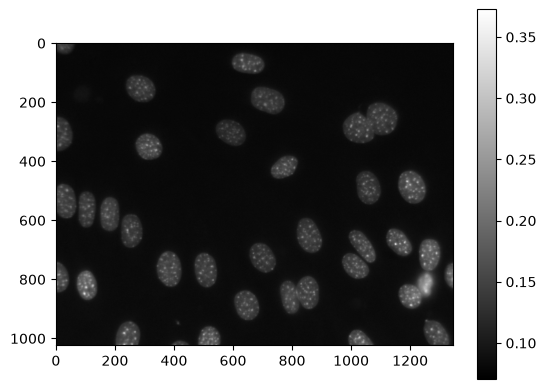

In [2]:
imgf = plt.imread("data/NIH3T3/im/dna-0.png")
plt.figure()
plt.imshow(imgf, cmap = "gray")
plt.colorbar()

**[Task 1.2.]()** Quantify the image into 256 bins:

In [3]:
img8 = (imgf * 255).round().astype(np.uint8)

**[Task 1.3.]()** Compute the image histogram:

In [4]:
h = np.zeros(256)

In [5]:
for i in range(256) :
    h[i] = np.sum(img8 == i)

Show the computed histogram:

<BarContainer object of 256 artists>

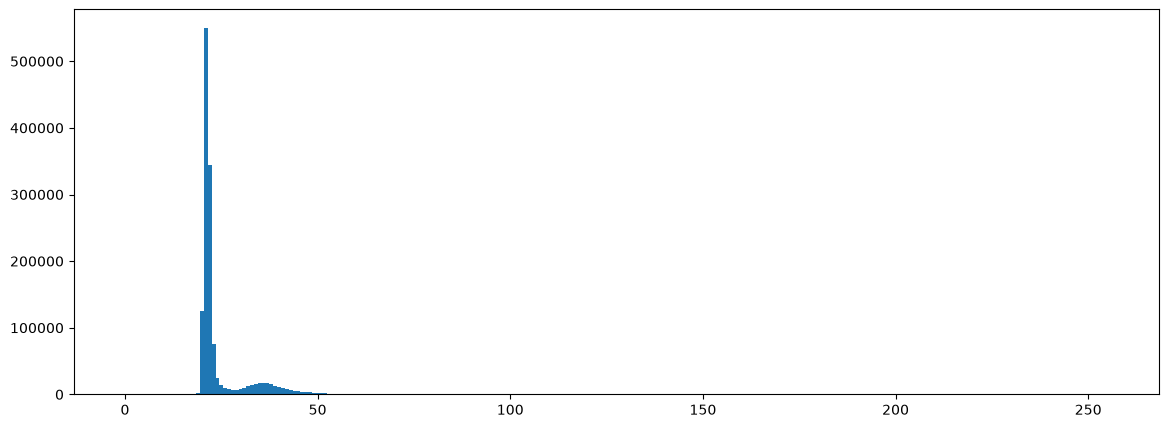

In [6]:
plt.figure(figsize=(14,5))
plt.bar(range(256), h, width=1)

**[Task 1.4.]()** Implement the method of Otsu:

In [7]:
sum_wcv = np.zeros(256)
for T in range(256) :
    sum_wcv[T] = (np.sum(h[:T]) * np.var(img8[img8 < T]) + (np.sum(h[T:]) * np.var(img8[img8 >= T])))

sum_wcv

/Users/tilmannstieglitz/Library/Mobile Documents/com~apple~CloudDocs/5.Semester/Bioinformatik/Bioinfo Praktikum/mobi-fs5-python/.venv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:4270: RuntimeWarning: Degrees of freedom <= 0 for slice
  return _methods._var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/tilmannstieglitz/Library/Mobile Documents/com~apple~CloudDocs/5.Semester/Bioinformatik/Bioinfo Praktikum/mobi-fs5-python/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/Users/tilmannstieglitz/Library/Mobile Documents/com~apple~CloudDocs/5.Semester/Bioinformatik/Bioinfo Praktikum/mobi-fs5-python/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


array([              nan,               nan,               nan,
                     nan,               nan,               nan,
                     nan,               nan,               nan,
                     nan,               nan,               nan,
                     nan,               nan,               nan,
                     nan,               nan,               nan,
                     nan, 62268423.49896931, 62231302.67756926,
       59818223.62454262, 47165648.8532488 , 27449150.57824365,
       18586354.36935249, 15253989.89752736, 13539656.28011815,
       12557445.78895864, 11933561.89796724, 11536254.18924297,
       11313729.00229156, 11275653.93934225, 11495860.3303481 ,
       12094366.7889171 , 13176916.55272644, 14767374.26909976,
       16902177.86318459, 19466392.13648611, 22316940.04301707,
       25216024.01878978, 28108330.89532448, 30810951.55526169,
       33287950.23202945, 35560795.1656556 , 37671210.8137913 ,
       39656813.25915194, 41533993.49633

In [8]:
T_best = np.nanargmin(sum_wcv)
print(T_best)
print(sum_wcv[T_best])

31
11275653.93934225


**[Task 1.5.]()** Perform Otsu thresholding:

In [9]:
img8.shape

(1024, 1344)

In [10]:
img8_otsu = img8.copy()

for x in range(img8.shape[0]) :
    for y in range(img8.shape[1]) :
        if img8[x, y] > T_best :
            img8_otsu[x, y] = 255
        else :
            img8_otsu[x, y] = 0

imgf_otsu = img8_otsu / 255

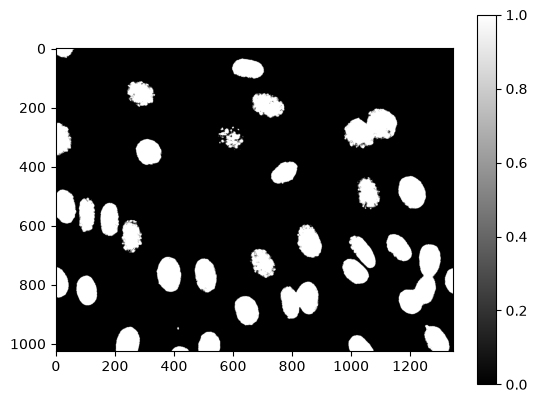

In [11]:
plt.figure()
plt.imshow(imgf_otsu, cmap="gray")
plt.colorbar()

**[Task 1.6.]()** Compute the Dice coefficient:

In [12]:
img8_gt = plt.imread("data/NIH3T3/gt/0.png")

def dice_coefficient(picture, ground_truth):
    return (2 * (picture * ground_truth).sum()) / (picture.sum() + ground_truth.sum())

dice_img8 = dice_coefficient(imgf_otsu, img8_gt)
dice_img8

np.float64(0.8701113873987207)